In [6]:
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import seaborn as sns
from sklearn.ensemble import GradientBoostingClassifier, RandomForestClassifier
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import classification_report, confusion_matrix, f1_score
from sklearn.model_selection import cross_val_score, train_test_split
from sklearn.preprocessing import OneHotEncoder
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import StandardScaler

sns.set_theme(style="whitegrid")

CLEAN_PATH = Path("../data/processed/netflix_clean.csv")
FIG_DIR = Path("../reports/figures")

df = pd.read_csv(CLEAN_PATH, parse_dates=["date_added"])

# Target: predict the content rating group from non-leaky features
print(df["rating"].value_counts())

rating
TV-MA       3205
TV-14       2157
TV-PG        861
R            799
PG-13        490
TV-Y7        333
TV-Y         306
PG           287
TV-G         220
NR            79
G             41
TV-Y7-FV       6
NC-17          3
UR             3
Name: count, dtype: int64


In [2]:
RATING_GROUPS = {
    "TV-Y": "Kids", "TV-Y7": "Kids", "TV-Y7-FV": "Kids",
    "TV-G": "Kids", "G": "Kids", "PG": "Kids", "TV-PG": "Kids",
    "TV-14": "Teens", "PG-13": "Teens",
    "TV-MA": "Mature", "R": "Mature", "NC-17": "Mature",
}

df["rating_group"] = df["rating"].map(RATING_GROUPS)

# NR / UR are "unrated", not an audience group, so they are excluded
model_df = df.dropna(subset=["rating_group"]).copy()
print(f"Rows used: {len(model_df)} (dropped {len(df) - len(model_df)} unrated)")
print(model_df["rating_group"].value_counts())
print((model_df["rating_group"].value_counts(normalize=True) * 100).round(1))

Rows used: 8708 (dropped 82 unrated)
rating_group
Mature    4007
Teens     2647
Kids      2054
Name: count, dtype: int64
rating_group
Mature    46.0
Teens     30.4
Kids      23.6
Name: proportion, dtype: float64


In [3]:
# Genres: one 0/1 column per genre (keep genres that appear 50+ times)
genre_dummies = model_df["listed_in"].str.get_dummies(sep=", ")
genre_dummies = genre_dummies.loc[:, genre_dummies.sum() >= 50]

# Countries: keep the top 10, group the rest as "Other"
top_countries = model_df["primary_country"].value_counts().head(10).index
country = model_df["primary_country"].where(
    model_df["primary_country"].isin(top_countries), "Other"
)

X = pd.concat(
    [
        pd.get_dummies(country, prefix="country"),
        genre_dummies.add_prefix("genre_"),
        (model_df["type"] == "Movie").astype(int).rename("is_movie"),
        model_df[["release_year", "duration_value"]],
    ],
    axis=1,
)
y = model_df["rating_group"]

print("Feature matrix:", X.shape)
print("Example features:", list(X.columns[:8]))

Feature matrix: (8708, 54)
Example features: ['country_Canada', 'country_France', 'country_India', 'country_Japan', 'country_Other', 'country_Pakistan', 'country_South Korea', 'country_Spain']


In [4]:
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=42, stratify=y
)
print(f"Train: {X_train.shape[0]} rows, Test: {X_test.shape[0]} rows")
print((y_test.value_counts(normalize=True) * 100).round(1))

Train: 6966 rows, Test: 1742 rows
rating_group
Mature    46.0
Teens     30.4
Kids      23.6
Name: proportion, dtype: float64


In [10]:
models = {
    "Logistic Regression": Pipeline([
        ("scale", StandardScaler()),
        ("clf", LogisticRegression(max_iter=1000, class_weight="balanced")),
    ]),
    "Random Forest": RandomForestClassifier(
        n_estimators=200, class_weight="balanced", random_state=42, n_jobs=-1
    ),
    "Gradient Boosting": GradientBoostingClassifier(random_state=42),
}

rows, fitted = [], {}
for name, model in models.items():
    model.fit(X_train, y_train)
    pred = model.predict(X_test)
    cv = cross_val_score(model, X_train, y_train, cv=5, scoring="accuracy")
    fitted[name] = model
    rows.append({
        "Model": name,
        "Test accuracy": round(float((pred == y_test).mean()), 3),
        "Macro F1": round(f1_score(y_test, pred, average="macro"), 3),
        "CV accuracy (5-fold)": round(float(cv.mean()), 3),
    })

results = pd.DataFrame(rows).sort_values("Macro F1", ascending=False)
display(results)

# Baseline: always guess the biggest group
baseline = float((y_test == y_train.mode()[0]).mean())
print(f"Baseline accuracy (always predict '{y_train.mode()[0]}'): {baseline:.3f}")

,Model,Test accuracy,Macro F1,CV accuracy (5-fold)
2,Gradient Boosting,0.679,0.654,0.664
0,Logistic Regression,0.646,0.644,0.641
1,Random Forest,0.626,0.622,0.619


Baseline accuracy (always predict 'Mature'): 0.460


Best model: Gradient Boosting

              precision    recall  f1-score   support

        Kids       0.85      0.64      0.73       411
       Teens       0.60      0.41      0.48       529
      Mature       0.66      0.88      0.75       802

    accuracy                           0.68      1742
   macro avg       0.70      0.64      0.65      1742
weighted avg       0.68      0.68      0.67      1742



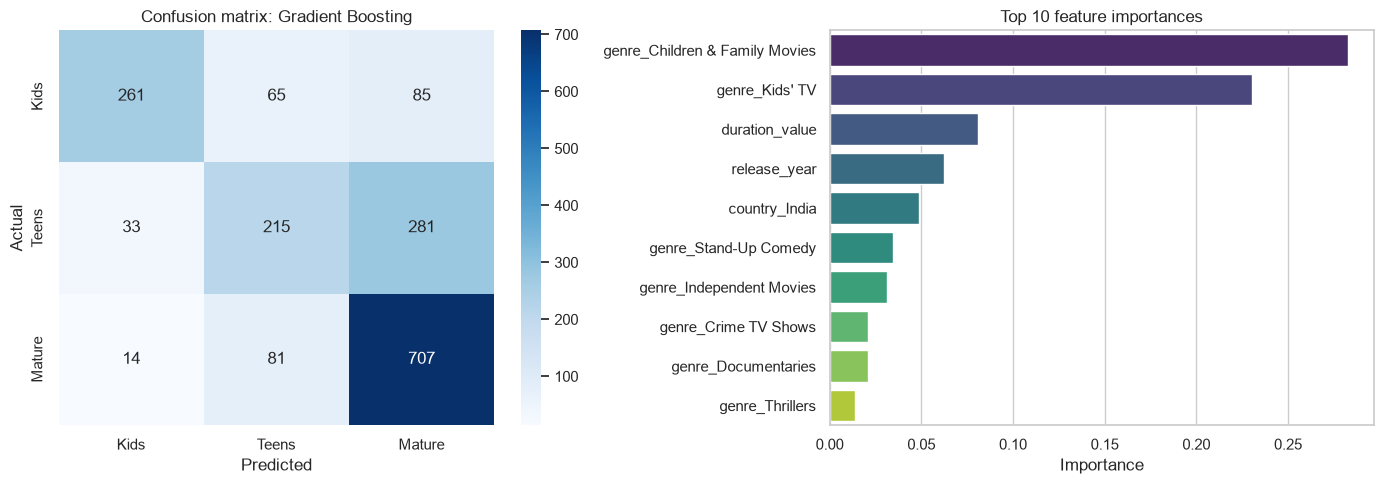

In [11]:
best_name = results.iloc[0]["Model"]
best = fitted[best_name]
pred = best.predict(X_test)
labels = ["Kids", "Teens", "Mature"]

print(f"Best model: {best_name}\n")
print(classification_report(y_test, pred, labels=labels))

fig, axes = plt.subplots(1, 2, figsize=(14, 5))

cm = confusion_matrix(y_test, pred, labels=labels)
sns.heatmap(cm, annot=True, fmt="d", cmap="Blues",
            xticklabels=labels, yticklabels=labels, ax=axes[0])
axes[0].set_title(f"Confusion matrix: {best_name}")
axes[0].set_xlabel("Predicted")
axes[0].set_ylabel("Actual")

importances = pd.Series(best.feature_importances_, index=X.columns).nlargest(10)
sns.barplot(x=importances.values, y=importances.index, hue=importances.index,
            palette="viridis", legend=False, ax=axes[1])
axes[1].set_title("Top 10 feature importances")
axes[1].set_xlabel("Importance")
axes[1].set_ylabel("")

plt.tight_layout()
fig.savefig(FIG_DIR / "classification_results.png", dpi=150, bbox_inches="tight")
plt.show()

## Summary

**Goal:** classify Netflix titles into an audience group (Kids / Teens / Mature) using genres, country, content type, release year and duration.

**Target:** the 14 raw ratings were mapped to 3 groups (Kids: TV-Y, TV-Y7, TV-Y7-FV, TV-G, G, PG, TV-PG; Teens: TV-14, PG-13; Mature: TV-MA, R, NC-17). Unrated titles (NR, UR; 82 rows) were excluded, leaving 8,708 rows. Data was split 80/20 with stratification.

**Models compared:**

| Model | Test accuracy | Macro F1 | CV accuracy |
|---|---|---|---|
| Gradient Boosting | 0.679 | 0.654 | 0.664 |
| Logistic Regression | 0.646 | 0.644 | 0.641 |
| Random Forest | 0.626 | 0.622 | 0.619 |
| Baseline (always "Mature") | 0.460 | - | - |

**Best model:** Gradient Boosting, about 22 points above the baseline. Cross-validation accuracy is close to test accuracy, so there is no sign of overfitting.

**Findings:** Mature titles are predicted well (recall 0.88) and Kids titles precisely (precision 0.85). Teens is the weakest group (F1 0.48); many Teens titles are predicted as Mature. Children's genres are the most important features.

**Limitations:** the dataset has no plot description or cast, so Teens and Mature content is hard to separate using only genre, country and duration. `duration_value` mixes minutes (movies) and seasons (TV shows), which the model partly handles through the `is_movie` feature. Adding plot text (TF-IDF) would likely improve accuracy.